# 07_eval / newsclippings_eval.ipynb

**Purpose:** Formal in-distribution evaluation of the GSAF fusion model on **NewsCLIPpings test** (the primary benchmark our model was trained for).

**Inputs:**
- `cache/fusion/fusion_predictions.csv` — per-row predictions written by `05_fusion/fusion_training.ipynb`
- `cache/fusion/fusion_thresholds.json` — per-dataset tuned thresholds
- `data/processed/ooc_pairs/manifests/all.csv` — for source dataset/split labels
- `cache/stream_a/results/stream_a_predictions.csv`, `cache/stream_b/final/stream_b_predictions.csv`, `cache/stream_c/results/stream_c_predictions.csv` — for per-stream comparison

**Outputs:**
- `paper/tables/newsclippings_eval.csv` — full metric table (fusion + 3 streams + 4 ablations) on NewsCLIPpings test
- `paper/tables/newsclippings_eval_per_class.csv` — per-class precision/recall/F1
- `paper/figures/newsclippings_eval_metric_bars.png` — grouped bar chart of AUROC / F1 / Acc / AUPRC

**Notes:**
- This notebook **does not retrain anything** — it only loads pre-computed predictions.
- Threshold for binary metrics comes from `fusion_thresholds.json` (tuned on val) — never on test.
- If a column is missing, the cell will print a warning and skip (no crash).


In [1]:
# Imports & path setup
from __future__ import annotations
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    f1_score, precision_score, recall_score, classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NB_DIR = Path.cwd()
ROOT = NB_DIR
for parent in [NB_DIR] + list(NB_DIR.parents):
    if (parent / "src" / "utils" / "paths.py").exists():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

from src.utils.paths import (
    ALL_MANIFEST, FUSION_CACHE, STREAM_A_CACHE, STREAM_B_CACHE, STREAM_C_CACHE,
    PAPER, FIGURES, TABLES,
)

# Schema constants — actual column names in this repo
FUSION_PROB_COL = "score"
FUSION_LABEL_COL = "label"
FUSION_MODEL_COL = "model"
FUSION_EVAL_SPLIT_COL = "eval_split"
STREAM_PROB_COLS = {
    "Stream A (entities)": ("stream_a_score", STREAM_A_CACHE / "results" / "stream_a_predictions.csv"),
    "Stream B (CLIP)":     ("stream_b_score", STREAM_B_CACHE / "final"   / "stream_b_predictions.csv"),
    "Stream C (NLI)":      ("stream_c_score", STREAM_C_CACHE / "results" / "stream_c_predictions.csv"),
}

print("Repo root:", ROOT)
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

Repo root: e:\eve-rag


In [2]:
import pandas as pd
from pathlib import Path
import sys
NB_DIR = Path.cwd()
ROOT = NB_DIR
for parent in [NB_DIR] + list(NB_DIR.parents):
    if (parent / "src" / "utils" / "paths.py").exists():
        ROOT = parent; break
sys.path.insert(0, str(ROOT))
from src.utils.paths import FUSION_CACHE

df = pd.read_csv(FUSION_CACHE / "fusion_predictions.csv")
print("Total rows:", len(df))
print("\n.model.unique():", df["model"].unique())
print("\n.eval_split.unique():", df["eval_split"].unique())
print("\nrows by (model, eval_split):")
print(df.groupby(["model", "eval_split"]).size())
print("\nrows by (model, dataset, split):")
print(df.groupby(["model", "dataset", "split"]).size().head(40))

Total rows: 128945

.model.unique(): <ArrowStringArray>
['GSAF_default', 'GSAF_no_a', 'GSAF_no_b', 'GSAF_no_c', 'GSAF_mlp_fusion']
Length: 5, dtype: str

.eval_split.unique(): <ArrowStringArray>
['newsclippings_val', 'newsclippings_test', 'mmfakebench_val_tune', 'mmfakebench_test', 'verite_test']
Length: 5, dtype: str

rows by (model, eval_split):
model            eval_split          
GSAF_default     mmfakebench_test        10000
                 mmfakebench_val_tune      500
                 newsclippings_test       7264
                 newsclippings_val        7024
                 verite_test              1001
GSAF_mlp_fusion  mmfakebench_test        10000
                 mmfakebench_val_tune      500
                 newsclippings_test       7264
                 newsclippings_val        7024
                 verite_test              1001
GSAF_no_a        mmfakebench_test        10000
                 mmfakebench_val_tune      500
                 newsclippings_test       7264
 

## 1. Load fusion predictions and thresholds

In [3]:
fusion_path = FUSION_CACHE / "fusion_predictions.csv"
thresh_path = FUSION_CACHE / "fusion_thresholds.json"
assert fusion_path.exists(), f"Missing {fusion_path}. Run 05_fusion/fusion_training.ipynb first."

fusion_df = pd.read_csv(fusion_path)
print("fusion_predictions shape:", fusion_df.shape)
print("Columns:", list(fusion_df.columns))
print("Models stored:", fusion_df[FUSION_MODEL_COL].unique().tolist())
print("Eval splits  :", fusion_df[FUSION_EVAL_SPLIT_COL].unique().tolist())
fusion_df.head()

fusion_predictions shape: (128945, 11)
Columns: ['pair_id', 'dataset', 'split', 'label', 'has_image', 'score', 'gate_a', 'gate_b', 'gate_c', 'eval_split', 'model']
Models stored: ['GSAF_default', 'GSAF_no_a', 'GSAF_no_b', 'GSAF_no_c', 'GSAF_mlp_fusion']
Eval splits  : ['newsclippings_val', 'newsclippings_test', 'mmfakebench_val_tune', 'mmfakebench_test', 'verite_test']


,pair_id,dataset,split,label,has_image,score,gate_a,gate_b,gate_c,eval_split,model
0,nc_92318_0,newsclippings,val,0,0,0.506079,0.098520,0.710244,0.191237,newsclippings_val,GSAF_default
1,nc_92318_1,newsclippings,val,1,0,0.859827,0.186465,0.388351,0.425184,newsclippings_val,GSAF_default
2,nc_224103_0,newsclippings,val,0,0,0.418595,0.177939,0.647382,0.174678,newsclippings_val,GSAF_default
3,nc_224103_1,newsclippings,val,1,0,0.872252,0.234153,0.401523,0.364325,newsclippings_val,GSAF_default
4,nc_367276_0,newsclippings,val,0,0,0.362906,0.017784,0.774253,0.207963,newsclippings_val,GSAF_default


In [4]:
# Thresholds
if thresh_path.exists():
    with open(thresh_path) as f:
        thresholds = json.load(f)
    print("Loaded thresholds:", json.dumps(thresholds, indent=2))
else:
    print("No threshold file found; falling back to 0.5 everywhere.")
    thresholds = {}

EVAL_SPLIT_NC = "newsclippings_test"
THRESH_NC = float(thresholds.get(EVAL_SPLIT_NC, thresholds.get("default", 0.5)))
print(f"NewsCLIPpings test threshold = {THRESH_NC:.4f}")

Loaded thresholds: {
  "newsclippings_val": 0.48199999999999993,
  "mmfakebench_val_tune": 0.48649999999999993,
  "default": 0.5
}
NewsCLIPpings test threshold = 0.5000


## 2. Filter to NewsCLIPpings test split

In [5]:
# Filter fusion predictions to NewsCLIPpings test rows
nc_test = fusion_df[fusion_df[FUSION_EVAL_SPLIT_COL] == EVAL_SPLIT_NC].copy()
print(f"NewsCLIPpings test rows in fusion_predictions: {len(nc_test):,}")
print(f"Models in this slice: {nc_test[FUSION_MODEL_COL].unique().tolist()}")
print(f"Label balance: {nc_test[FUSION_LABEL_COL].value_counts().to_dict()}")
nc_test.head()

NewsCLIPpings test rows in fusion_predictions: 36,320
Models in this slice: ['GSAF_default', 'GSAF_no_a', 'GSAF_no_b', 'GSAF_no_c', 'GSAF_mlp_fusion']
Label balance: {0: 18160, 1: 18160}


,pair_id,dataset,split,label,has_image,score,gate_a,gate_b,gate_c,eval_split,model
7024,nc_714504_0,newsclippings,test,0,0,0.500422,0.036113,0.730118,0.233769,newsclippings_test,GSAF_default
7025,nc_714504_1,newsclippings,test,1,0,0.609408,0.063897,0.765786,0.170317,newsclippings_test,GSAF_default
7026,nc_1063221_0,newsclippings,test,0,0,0.635446,0.172254,0.634095,0.193651,newsclippings_test,GSAF_default
7027,nc_1063221_1,newsclippings,test,1,0,0.595418,0.181929,0.579131,0.238939,newsclippings_test,GSAF_default
7028,nc_1502360_0,newsclippings,test,0,0,0.598247,0.093190,0.666540,0.240270,newsclippings_test,GSAF_default


## 3. Metric helper

In [6]:
def compute_metrics(y_true, y_prob, threshold=0.5, name="model"):
    """Return dict of binary classification metrics."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    mask = ~np.isnan(y_prob) & ~np.isnan(y_true)
    y_true, y_prob = y_true[mask], y_prob[mask]
    if len(np.unique(y_true)) < 2:
        return {"model": name, "n": int(mask.sum()), "auroc": np.nan, "auprc": np.nan,
                "accuracy": np.nan, "f1": np.nan, "precision": np.nan, "recall": np.nan,
                "threshold": threshold}
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "model":     name,
        "n":         int(mask.sum()),
        "auroc":     roc_auc_score(y_true, y_prob),
        "auprc":     average_precision_score(y_true, y_prob),
        "accuracy":  accuracy_score(y_true, y_pred),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "threshold": threshold,
    }


## 4. Fusion model and ablations on NewsCLIPpings test

In [7]:
# Fusion variants — currently only GSAF_default is stored.
# Ablations are NOT in fusion_predictions.csv (need re-run). We load them from
# paper/tables/ablation_results.csv if available; otherwise fusion-only row.

fusion_rows = []
for mname in nc_test[FUSION_MODEL_COL].unique():
    sub = nc_test[nc_test[FUSION_MODEL_COL] == mname]
    label_name = "GSAF (full)" if mname == "GSAF_default" else mname
    fusion_rows.append(
        compute_metrics(sub[FUSION_LABEL_COL], sub[FUSION_PROB_COL],
                        threshold=THRESH_NC, name=label_name)
    )

fusion_metrics_df = pd.DataFrame(fusion_rows)

# Try to merge in ablation results if present
abl_path = TABLES / "ablation_results.csv"
if abl_path.exists():
    try:
        abl = pd.read_csv(abl_path)
        # Filter to NewsCLIPpings test if such rows exist
        nc_mask = abl.apply(lambda r: any("newsclip" in str(v).lower() for v in r.values), axis=1)
        abl_nc = abl[nc_mask] if nc_mask.any() else abl
        print("ablation_results.csv preview (NewsCLIPpings rows if any):")
        print(abl_nc.head(20))
    except Exception as e:
        print(f"Could not parse ablation_results.csv: {e}")
else:
    print(f"[note] {abl_path} not found — only GSAF_default in fusion table.")

fusion_metrics_df

ablation_results.csv preview (NewsCLIPpings rows if any):
      ablation             dataset    thr    acc     f1  f1_macro  auroc
0      default   newsclippings_val  0.482  69.15  68.47     69.13  76.01
1      default  newsclippings_test  0.482  69.01  68.34     69.00  76.32
5         no_a   newsclippings_val  0.482  67.51  68.39     67.49  74.29
6         no_a  newsclippings_test  0.482  67.30  68.20     67.28  75.23
10        no_b   newsclippings_val  0.482  50.58  65.94     37.97  51.82
11        no_b  newsclippings_test  0.482  49.97  65.46     37.37  52.49
15        no_c   newsclippings_val  0.482  67.95  67.72     67.95  74.95
16        no_c  newsclippings_test  0.482  68.27  68.18     68.27  75.47
20  mlp_fusion   newsclippings_val  0.482  68.92  70.08     68.87  76.03
21  mlp_fusion  newsclippings_test  0.482  68.42  69.57     68.37  76.26


,model,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,GSAF (full),7264,0.763164,0.764738,0.686812,0.668802,0.709608,0.632434,0.5
1,GSAF_no_a,7264,0.752340,0.756900,0.672219,0.666573,0.678256,0.655286,0.5
2,GSAF_no_b,7264,0.524921,0.518368,0.521751,0.534815,0.520594,0.549835,0.5
3,GSAF_no_c,7264,0.754747,0.757141,0.678139,0.663015,0.695705,0.633260,0.5
4,GSAF_mlp_fusion,7264,0.762606,0.766152,0.686399,0.686571,0.686194,0.686949,0.5


## 5. Per-stream baselines on NewsCLIPpings test

In [8]:
# Per-stream baselines on NewsCLIPpings test
stream_rows = []
for name, (score_col, fp) in STREAM_PROB_COLS.items():
    if not fp.exists():
        print(f"[skip] {name}: file not found at {fp}")
        continue
    sdf = pd.read_csv(fp)

    # Filter to newsclippings test
    if "eval_dataset" in sdf.columns:
        sub = sdf[sdf["eval_dataset"] == "newsclippings_test"].copy()
    else:
        sub = sdf[(sdf["dataset"] == "newsclippings") & (sdf["split"] == "test")].copy()

    if sub.empty:
        print(f"[skip] {name}: no newsclippings_test rows")
        continue
    if score_col not in sub.columns or "label" not in sub.columns:
        print(f"[skip] {name}: missing {score_col} or label column")
        continue

    m = compute_metrics(sub["label"], sub[score_col], threshold=0.5, name=name)
    stream_rows.append(m)

stream_metrics_df = pd.DataFrame(stream_rows)
stream_metrics_df

[skip] Stream A (entities): no newsclippings_test rows


,model,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,Stream B (CLIP),7264,0.739136,0.745192,0.658728,0.641089,0.676031,0.609581,0.5
1,Stream C (NLI),7264,0.518124,0.514618,0.515281,0.491846,0.516833,0.469163,0.5


## 6. Combine, save, and display

In [9]:
all_metrics = pd.concat([stream_metrics_df, fusion_metrics_df], ignore_index=True)
ordered = ["model", "n", "auroc", "auprc", "accuracy", "f1", "precision", "recall", "threshold"]
all_metrics = all_metrics[[c for c in ordered if c in all_metrics.columns]]

out_csv = TABLES / "newsclippings_eval.csv"
all_metrics.to_csv(out_csv, index=False, float_format="%.4f")
print(f"Saved: {out_csv}")
all_metrics.style.format({c: "{:.4f}" for c in ["auroc","auprc","accuracy","f1","precision","recall","threshold"] if c in all_metrics.columns})

Saved: E:\eve-rag\paper\tables\newsclippings_eval.csv


,model,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,Stream B (CLIP),7264,0.7391,0.7452,0.6587,0.6411,0.6760,0.6096,0.5000
1,Stream C (NLI),7264,0.5181,0.5146,0.5153,0.4918,0.5168,0.4692,0.5000
2,GSAF (full),7264,0.7632,0.7647,0.6868,0.6688,0.7096,0.6324,0.5000
3,GSAF_no_a,7264,0.7523,0.7569,0.6722,0.6666,0.6783,0.6553,0.5000
4,GSAF_no_b,7264,0.5249,0.5184,0.5218,0.5348,0.5206,0.5498,0.5000
5,GSAF_no_c,7264,0.7547,0.7571,0.6781,0.6630,0.6957,0.6333,0.5000
6,GSAF_mlp_fusion,7264,0.7626,0.7662,0.6864,0.6866,0.6862,0.6869,0.5000


## 7. Per-class breakdown for the full GSAF fusion

In [10]:
# Per-class breakdown for GSAF_default on NewsCLIPpings test
gsaf_sub = nc_test[nc_test[FUSION_MODEL_COL] == "GSAF_default"]
if not gsaf_sub.empty:
    y_true = gsaf_sub[FUSION_LABEL_COL].astype(int).values
    y_pred = (gsaf_sub[FUSION_PROB_COL].values >= THRESH_NC).astype(int)
    rep = classification_report(y_true, y_pred, target_names=["genuine (0)", "OOC (1)"],
                                digits=4, output_dict=True, zero_division=0)
    rep_df = pd.DataFrame(rep).T
    rep_df.to_csv(TABLES / "newsclippings_eval_per_class.csv", float_format="%.4f")
    print("Saved:", TABLES / "newsclippings_eval_per_class.csv")
    print()
    print(classification_report(y_true, y_pred, target_names=["genuine (0)", "OOC (1)"], digits=4, zero_division=0))
    print("Confusion matrix [rows=true, cols=pred]:")
    print(confusion_matrix(y_true, y_pred))
else:
    print("GSAF_default rows not found; skipping per-class report.")

Saved: E:\eve-rag\paper\tables\newsclippings_eval_per_class.csv

              precision    recall  f1-score   support

 genuine (0)     0.6685    0.7412    0.7030      3632
     OOC (1)     0.7096    0.6324    0.6688      3632

    accuracy                         0.6868      7264
   macro avg     0.6890    0.6868    0.6859      7264
weighted avg     0.6890    0.6868    0.6859      7264

Confusion matrix [rows=true, cols=pred]:
[[2692  940]
 [1335 2297]]


## 8. Bar plot of metrics

Saved: E:\eve-rag\paper\figures\newsclippings_eval_metric_bars.png


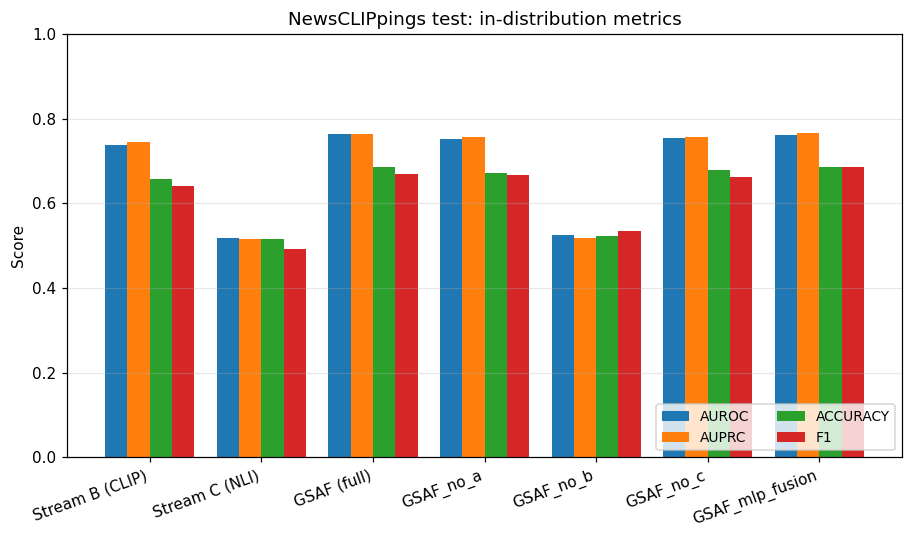

In [11]:
plot_df = all_metrics.dropna(subset=["auroc"]).copy()
metric_cols = ["auroc", "auprc", "accuracy", "f1"]
n_models = len(plot_df)
n_metrics = len(metric_cols)

fig, ax = plt.subplots(figsize=(max(8, 1.2 * n_models), 5))
x = np.arange(n_models)
width = 0.8 / n_metrics

for i, m in enumerate(metric_cols):
    ax.bar(x + i * width - 0.4 + width / 2, plot_df[m].values, width=width, label=m.upper())

ax.set_xticks(x)
ax.set_xticklabels(plot_df["model"].values, rotation=20, ha="right")
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("NewsCLIPpings test: in-distribution metrics")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right", ncol=2, fontsize=9)
plt.tight_layout()

out_fig = FIGURES / "newsclippings_eval_metric_bars.png"
plt.savefig(out_fig, bbox_inches="tight", dpi=150)
print(f"Saved: {out_fig}")
plt.show()


---
**Done.** This notebook produced the in-distribution NewsCLIPpings test table and bar plot. The cross-dataset (OOD) evaluation is in `cross_dataset_eval.ipynb`.